### Task 3: Set up a procedure to train load surrogate models that map the 10-minute DELs as function of the inputs {$u$, $\sigma_u$, $\alpha$} and which has capability to represent the uncertainty in the surrogate model estimates $X_M$ — e.g., by running an ensemble or by training a probabilistic ML model.

In [227]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

InputData = pd.read_excel('ML_ExampleDataSet.xlsx','InputVariables')
InputData = InputData.set_index('Sample_No',drop = False) # Make the "Sample_No" column as index of the data

TargetData = pd.read_excel('ML_ExampleDataSet.xlsx','LoadResults')
TargetData.set_index('PointNo', drop = False, inplace = True) # Make the "PointNo" column as index of the data

In [228]:
AllInputData = InputData.where(InputData['Sample_No']==TargetData['PointNo'])
AllTargetData = TargetData.where(TargetData['PointNo']==InputData['Sample_No'])
AllInputData.drop(columns = 'Sample_No', inplace = True)
AllTargetData.drop(columns = 'PointNo', inplace = True)
AllInputData = AllInputData[["U", "SigmaU", "Alpha"]]
nsamples = AllInputData['U'].count() # Find the total number of data points in the data frame
FeatureNames = AllInputData.columns.values
DependentVariableNames = AllTargetData.columns.values
print('Feature names: ', FeatureNames)
print('Dependent variable names: ', DependentVariableNames)
print(AllInputData.iloc[:,0].values)

Feature names:  ['U' 'SigmaU' 'Alpha']
Dependent variable names:  ['Tower_top_fore_aft_M_x' 'Tower_top_side2side_M_y'
 'Tower_base_fore_aft_M_x' 'Tower_base_side2side_M_y' 'Yaw_moment_M_z'
 'Main_shaft_torsion_M_z' 'Blade_root_flapwise_M_x'
 'Blade_root_edgewise_M_y']
[ 4.         10.1507576   6.81346652 ... 13.32617204  9.2987816
 19.89821019]


In [229]:
# Building a design matrix for a polynomial of 3rd order
def DesignMatrixO3(X):
    ndim = X.shape[1] 
    npoints = X.shape[0]
    m = int(((ndim-1)/2)*ndim)
    Xmatrix = np.zeros((npoints,3*ndim + 3*m + 1))
    columncount = 0
    Xmatrix[:,columncount] = np.ones(npoints)
    for i in range(ndim):
        columncount+=1
        Xmatrix[:,columncount] = X[:,i]

    for i in range(ndim -1):
        for j in range(i+1,ndim):
            columncount+= 1
            Xmatrix[:,columncount] = X[:,i]*X[:,j]

    for i in range(ndim):
        columncount+= 1
        Xmatrix[:,columncount] = X[:,i]**2

    for i in range(ndim-1):
        for j in range(i+1,ndim):
            columncount+= 1
            Xmatrix[:,columncount] = (X[:,i]**2)*X[:,j]

    for i in range(ndim-1):
        for j in range(i+1,ndim):
            columncount+= 1
            Xmatrix[:,columncount] = X[:,i]*(X[:,j]**2)

    for i in range(ndim):
        columncount+=1
        Xmatrix[:,columncount] = X[:,i]**3
    return Xmatrix


def PredictPolyO3(X,Alsq):
    Xmatrix = DesignMatrixO3(X)
    Y = np.dot(Xmatrix,Alsq)
    return Y

In [230]:
# MAKE A 3-RD ORDER POLYNOMIAL FIT TO THE DATA USING THE HELPER FUNCTIONS GIVEN ABOVE
import numpy as np
Y1 = AllTargetData['Blade_root_flapwise_M_x']
X = AllInputData[['U','SigmaU','Alpha']].values

# Create the design matrix for a 3rd order polynomial
Xmatrix = DesignMatrixO3(X)

XX = np.dot(Xmatrix.T, Xmatrix)     
XY = np.dot(Xmatrix.T, Y1)
Alsq = np.linalg.solve(XX, XY)
Alsq.shape

Ypred_O3 = np.dot(Xmatrix, Alsq)

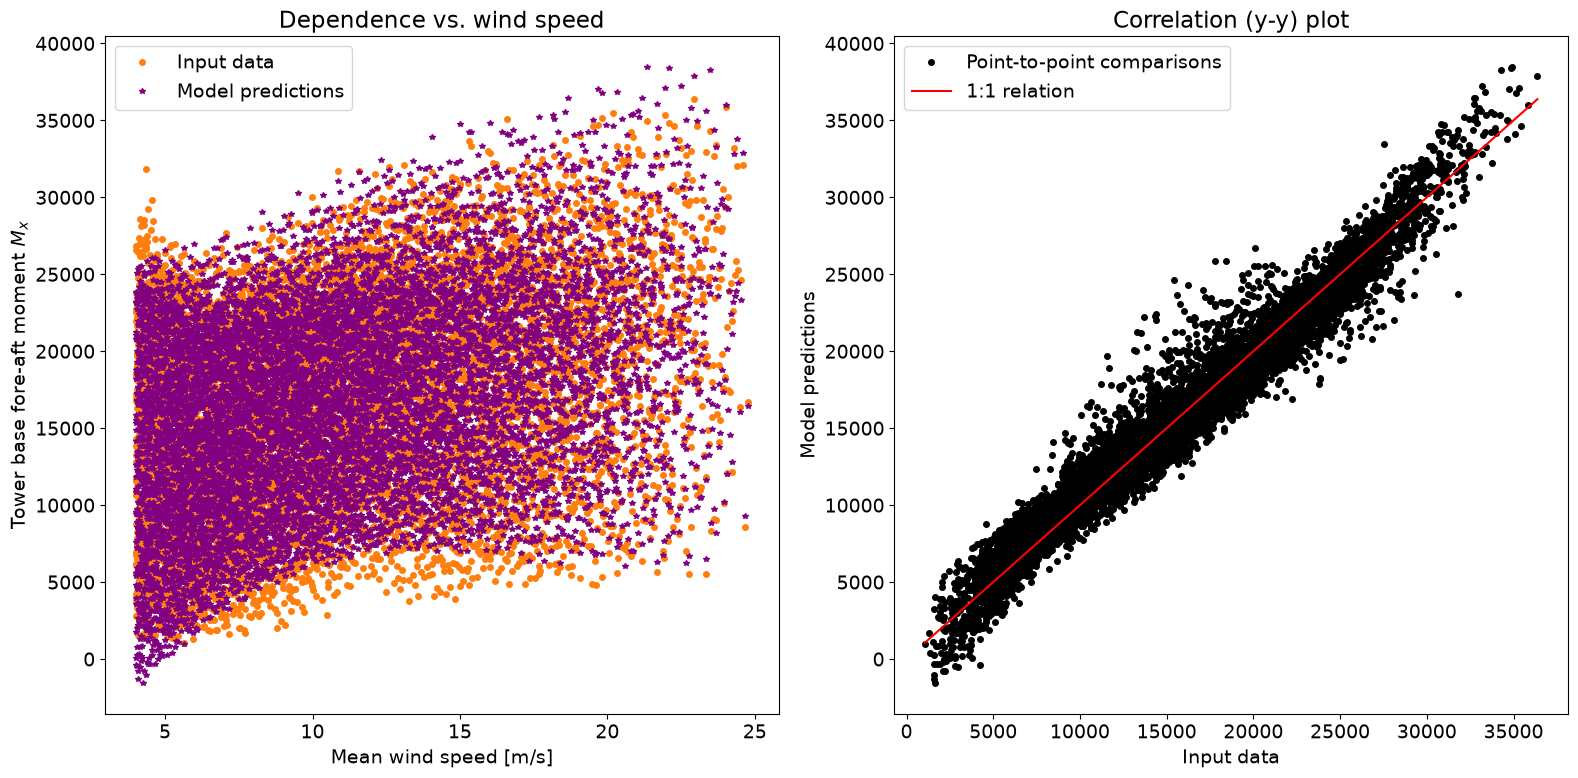

In [231]:
# VISUALISE RESULTS FROM THE PREDICTION
plt.rc('font', size=14) 
fig2a,axs2a = plt.subplots(1,2,figsize = (16,8))
plt.setp(axs2a[0], title = 'Dependence vs. wind speed', xlabel = 'Mean wind speed [m/s]', ylabel = 'Tower base fore-aft moment $M_x$')
plt.setp(axs2a[1], title = 'Correlation (y-y) plot', xlabel = 'Input data', ylabel = 'Model predictions')
axs2a[0].plot(AllInputData['U'], AllTargetData['Blade_root_flapwise_M_x'],'o',markersize = 4,color = 'C1')
axs2a[0].plot(AllInputData['U'], Ypred_O3,'*', markersize = 4,color = 'purple')
axs2a[0].legend(['Input data','Model predictions'])
axs2a[1].plot(AllTargetData['Blade_root_flapwise_M_x'], Ypred_O3,'ok', markersize = 4)
axs2a[1].plot(np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),\
             np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),'-r')
axs2a[1].legend(['Point-to-point comparisons','1:1 relation'])
plt.tight_layout()             
plt.show()

In [232]:
Rsq_poly = 1 - np.sum( (Y1 - Ypred_O3)**2) / np.sum((Y1 - np.mean(Y1))**2)
Rsq_corr_poly = (np.corrcoef(Y1,Ypred_O3)[0,1])**2 # R-squared with the correlation coefficient
RMSE_poly = np.sqrt( np.mean((Y1 - Ypred_O3)**2))
print('R-square of polynomial model: ' + str(Rsq_poly))
print('R-square computed through correlations: ' + str(Rsq_corr_poly))
print('RMSE of polynomial model: ' + str(RMSE_poly))

R-square of polynomial model: 0.9543421453167475
R-square computed through correlations: 0.954342145316748
RMSE of polynomial model: 1418.2512982146113


In [233]:
epsilon = Y1 - Ypred_O3
bias = np.mean(epsilon)
variance = np.var(epsilon)
print('Bias of polynomial model: ' + str(bias))
print('Variance of polynomial model: ' + str(variance))

Bias of polynomial model: -4.281004319687883e-12
Variance of polynomial model: 2011436.7448874312


### Model 1: Random Forest

In [234]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split


RFregressor = RandomForestRegressor(n_estimators=60, random_state=1)

In [235]:
# Split the data into training and testing sets
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y1, test_size=0.2, random_state=1, shuffle=True)

# Fit the model
RFregressor.fit(Xtrain, Ytrain)
Ypred_RF = RFregressor.predict(Xtest)

# Calculate R², RMSE, and MAE for the Random Forest model
r2_RF = r2_score(Ytest, Ypred_RF)
rmse_RF = np.sqrt(mean_squared_error(Ytest, Ypred_RF))
mae_RF = mean_absolute_error(Ytest, Ypred_RF)

In [236]:
# Get the feature importances from the Random Forest model
print(f"RF Test R²   = {r2_RF:.4f}")
print(f"RF Test RMSE = {rmse_RF:.4f}")
print(f"RF Test MAE  = {mae_RF:.4f}")

RF Test R²   = 0.9611
RF Test RMSE = 1330.3477
RF Test MAE  = 887.2984


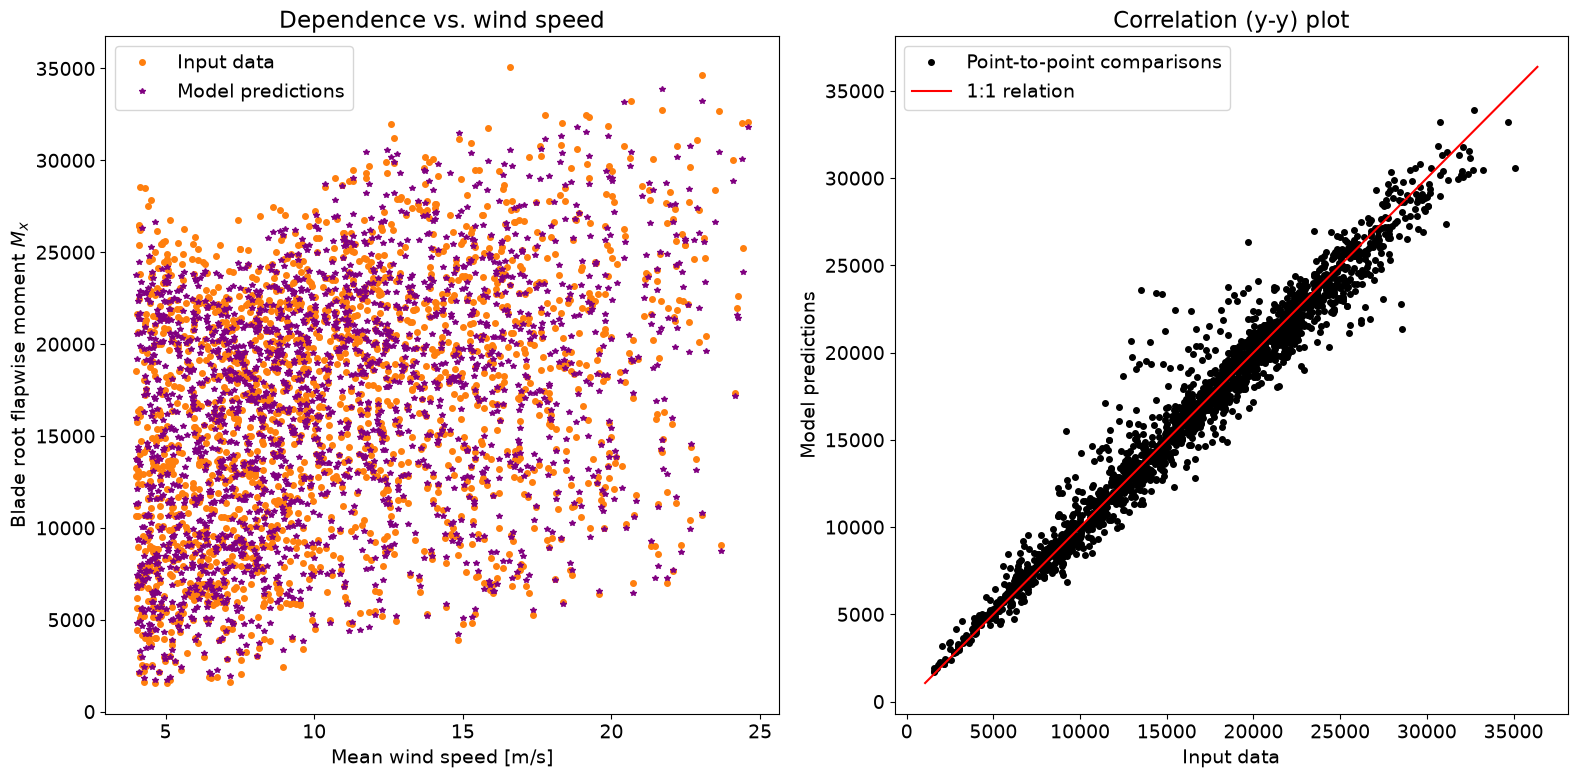

In [237]:
# VISUALISE RESULTS FROM THE PREDICTION
plt.rc('font', size=14) 
fig2b,axs2b = plt.subplots(1,2,figsize = (16,8))

plt.setp(axs2b[0], title = 'Dependence vs. wind speed', xlabel = 'Mean wind speed [m/s]', ylabel = 'Blade root flapwise moment $M_x$')
plt.setp(axs2b[1], title = 'Correlation (y-y) plot', xlabel = 'Input data', ylabel = 'Model predictions')

axs2b[0].plot(Xtest[:,0], Ytest,'o', markersize = 4,color = 'C1')
axs2b[0].plot(Xtest[:,0], Ypred_RF,'*',markersize = 4,color = 'purple')
axs2b[0].legend(['Input data', 'Model predictions'])

axs2b[1].plot(Ytest, Ypred_RF,'ok',markersize = 4)
axs2b[1].plot(np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),\
             np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),'-r')
axs2b[1].legend(['Point-to-point comparisons','1:1 relation'])

plt.tight_layout()             
plt.show()

### Model 2: Artificial Neural Network

In [238]:
import sklearn
import sklearn.neural_network


In [239]:
X = (AllInputData - AllInputData.mean(axis=0))/AllInputData.std(axis=0)

# Normalize the dataset
Xscaler = sklearn.preprocessing.StandardScaler()
Yscaler = sklearn.preprocessing.StandardScaler()

Xscaler = Xscaler.fit(AllInputData.values)
Yscaler = Yscaler.fit(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1,1))

# Split into training and testing
TrainTestRatio = 0.8
N = len(AllInputData)
Xtrain = AllInputData.values[0:int(N*TrainTestRatio),:]
Xtest = AllInputData.values[int(N*TrainTestRatio):,:]

Ytrain = Yscaler.transform(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1,1))[0:int(N*TrainTestRatio),:]
Ytest = Yscaler.transform(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1,1))[int(N*TrainTestRatio):,:]

In [240]:
# Performance of different activation functions -> TANH
ANNmodel = sklearn.neural_network.MLPRegressor()
ANNmodel.set_params(activation = 'tanh', hidden_layer_sizes = (10, 10))
ANNmodel.fit(Xtrain, Ytrain)

print( 'Train set r-square: ' + str(ANNmodel.score(Xtrain, Ytrain)))
print( 'Test set r-square: ' + str(ANNmodel.score(Xtest, Ytest)))
print( 'Score of the model: ' + str(ANNmodel.score(AllInputData, Y1)))

c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Train set r-square: 0.9657639857024972
Test set r-square: 0.9666151355041108
Score of the model: -6.3138487222136295


c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but MLPRegressor was fitted without feature names
  warnings.warn(


In [241]:
ANNmodel = sklearn.neural_network.MLPRegressor()
ANNmodel.set_params(activation = 'relu', hidden_layer_sizes = (10, 10))
ANNmodel.fit(Xtrain, Ytrain)

print( 'Train set r-square: ' + str(ANNmodel.score(Xtrain,Ytrain)))
print( 'Test set r-square: ' + str(ANNmodel.score(Xtest,Ytest)))
print( 'Score of the model: ' + str(ANNmodel.score(AllInputData, Y1)))

c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Train set r-square: 0.9626537381520395
Test set r-square: 0.9629911690940969
Score of the model: -6.313858913271628


c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but MLPRegressor was fitted without feature names
  warnings.warn(


In [242]:
# Compute Model Predictions for the whole dataset
Yout = Yscaler.inverse_transform(ANNmodel.predict(Xtrain).reshape(-1, 1))
Yout_test = Yscaler.inverse_transform(ANNmodel.predict(Xtest).reshape(-1, 1))

In [243]:
# Save variables for reference 
r2_ann = sklearn.metrics.r2_score(Ytest, Yout_test)
rmse_ann = np.sqrt(sklearn.metrics.mean_squared_error(Ytest, Yout_test))
mae_ann = sklearn.metrics.mean_absolute_error(Ytest,Yout_test)

print( 'Train set r-square: ' + str(ANNmodel.score(Xtrain,Ytrain)))
print( 'Test set r-square: ' + str(ANNmodel.score(Xtest,Ytest)))
print("\n")

# Print the stats 
print( 'R2 of ANN model: ' + str(r2_ann))
print( 'RMSE of ANN model: ' + str(rmse_ann))
print( 'MAE of ANN model: ' + str(mae_ann))

Train set r-square: 0.9626537381520395
Test set r-square: 0.9629911690940969


R2 of ANN model: -317837649.97751474
RMSE of ANN model: 17869.84238540289
MAE of ANN model: 16629.92543240628


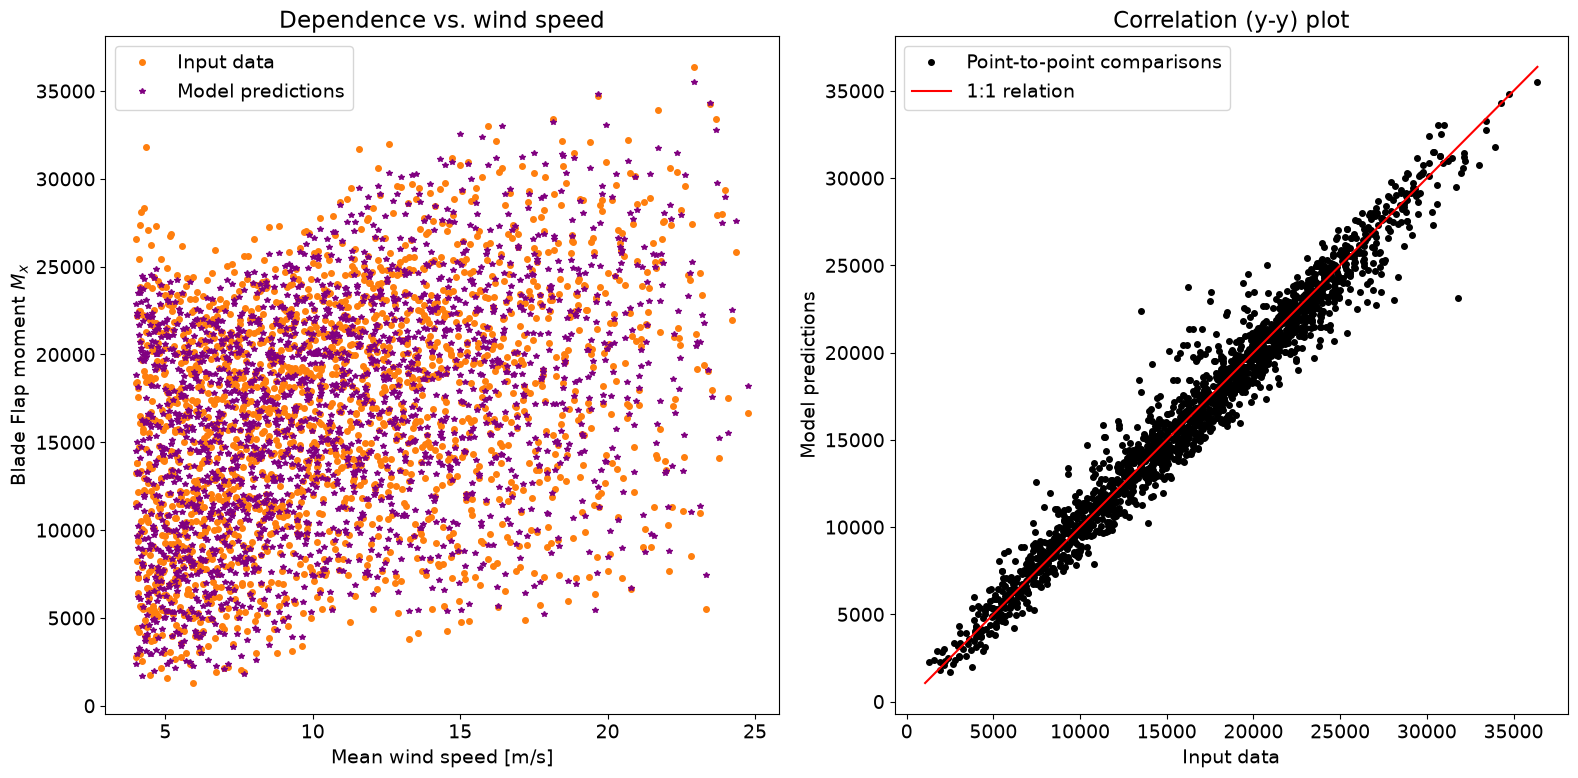

In [244]:
# VISUALISE RESULTS FROM THE PREDICTION 
plt.rc('font', size=14) 
fig3,axs3 = plt.subplots(1,2,figsize = (16,8))
plt.setp(axs3[0], title = 'Dependence vs. wind speed', xlabel = 'Mean wind speed [m/s]',ylabel = 'Blade Flap moment $M_x$')
plt.setp(axs3[1], title = 'Correlation (y-y) plot', xlabel = 'Input data',ylabel = 'Model predictions')
axs3[0].plot(Xtest[:,0],Yscaler.inverse_transform(Ytest),'o',markersize = 4,color = 'C1')
axs3[0].plot(Xtest[:,0],Yout_test,'*',markersize = 4,color = 'purple')
axs3[0].legend(['Input data','Model predictions'])
axs3[1].plot(Yscaler.inverse_transform(Ytest),Yout_test,'ok',markersize = 4)
axs3[1].plot(np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),\
             np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),'-r')
axs3[1].legend(['Point-to-point comparisons','1:1 relation'])
plt.tight_layout()     
plt.show()

### Evaluation

In [245]:
import prettytable as pt

# Compare R2, RMSE and score of RF and ANN models 
table = pt.PrettyTable()
table.field_names = ["Model", "R²", "RMSE", "MAE"]
table.add_row(["Random Forest", f"{r2_RF:.4f}", f"{rmse_RF:.4f}", f"{mae_RF:.4f}"])
table.add_row(["Artificial Neural Network", f"{r2_ann:.4f}", f"{rmse_ann:.4f}", f"{mae_ann:.4f}"])

print(table)

+---------------------------+-----------------+------------+------------+
|           Model           |        R²       |    RMSE    |    MAE     |
+---------------------------+-----------------+------------+------------+
|       Random Forest       |      0.9611     | 1330.3477  |  887.2984  |
| Artificial Neural Network | -317837649.9775 | 17869.8424 | 16629.9254 |
+---------------------------+-----------------+------------+------------+
